## Problem 16
Frequency domain filtering using Ideal, Butterworth and Gaussian filters.

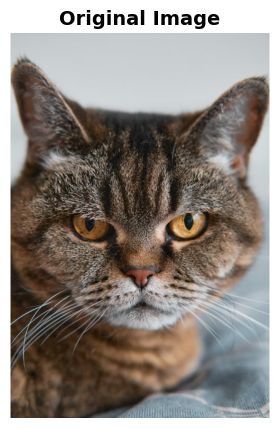

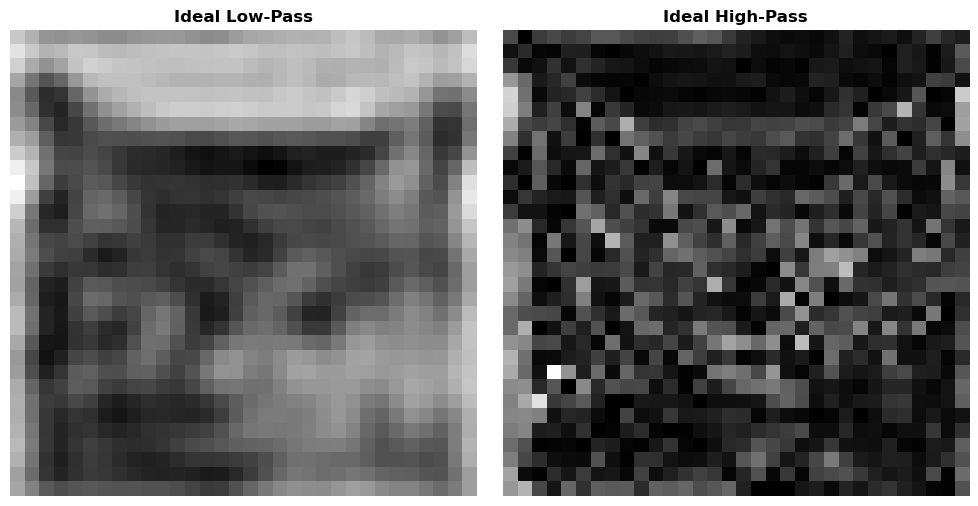

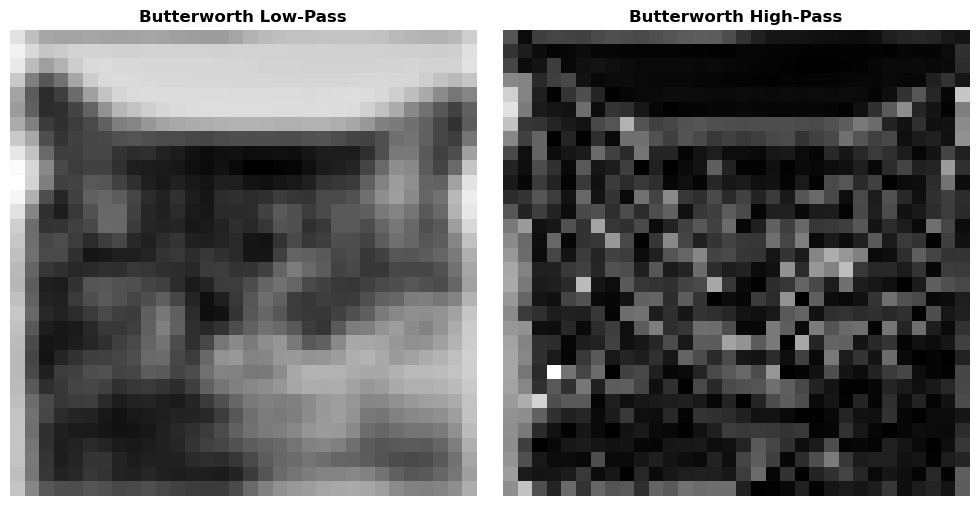

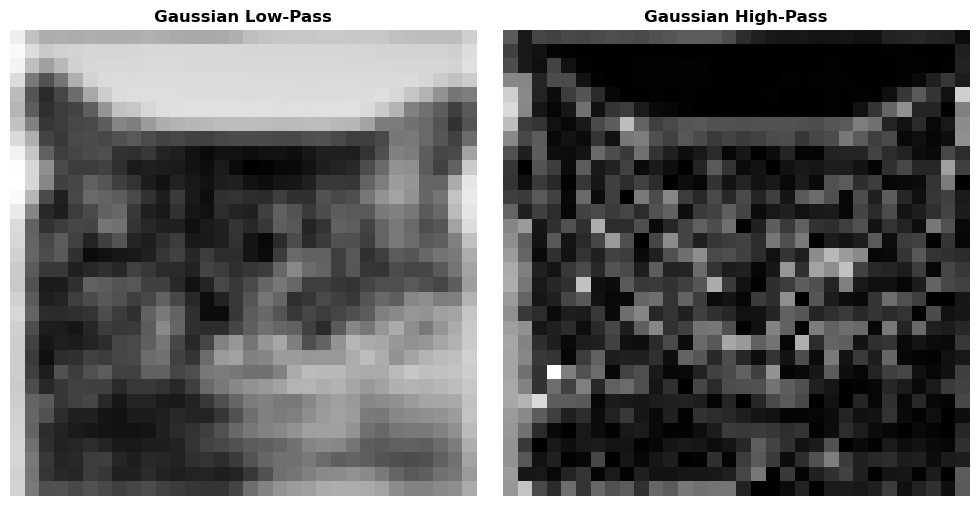

In [3]:
import cv2
import math
import matplotlib.pyplot as plt
import numpy as np

source = cv2.imread("cat.png")
source_height, source_width = source.shape[:2]
# A small image makes the manual DFT easy and fast to run.
rows = 16
cols = 16
image = np.zeros((rows, cols), dtype=float)
for row in range(rows):
    for col in range(cols):
        old_row = row * source_height // rows
        old_col = col * source_width // cols
        blue = int(source[old_row, old_col, 0])
        green = int(source[old_row, old_col, 1])
        red = int(source[old_row, old_col, 2])
        image[row, col] = 0.114 * blue + 0.587 * green + 0.299 * red

def transform(values, inverse=False):
    length = len(values)
    result = [0j] * length
    sign = 1 if inverse else -1
    for output in range(length):
        total = 0j
        for index in range(length):
            angle = sign * 2 * math.pi * output * index / length
            total += values[index] * complex(math.cos(angle), math.sin(angle))
        result[output] = total / length if inverse else total
    return result

def transform_2d(matrix, inverse=False):
    temporary = np.zeros((rows, cols), dtype=complex)
    result = np.zeros((rows, cols), dtype=complex)
    for row in range(rows):
        values = transform([matrix[row, col] for col in range(cols)], inverse)
        for col in range(cols):
            temporary[row, col] = values[col]
    for col in range(cols):
        values = transform([temporary[row, col] for row in range(rows)], inverse)
        for row in range(rows):
            result[row, col] = values[row]
    return result

def shift(matrix):
    result = np.zeros_like(matrix)
    for row in range(rows):
        for col in range(cols):
            result[row, col] = matrix[(row + rows // 2) % rows, (col + cols // 2) % cols]
    return result

spectrum = shift(transform_2d(image))
D0 = 8
order = 2
filters = [np.zeros((rows, cols)) for item in range(6)]
for row in range(rows):
    for col in range(cols):
        distance = math.sqrt((row - rows // 2) ** 2 + (col - cols // 2) ** 2)
        filters[0][row, col] = 1 if distance <= D0 else 0
        filters[1][row, col] = 1 - filters[0][row, col]
        filters[2][row, col] = 1 / (1 + (distance / D0) ** (2 * order))
        filters[3][row, col] = 1 - filters[2][row, col]
        filters[4][row, col] = math.exp(-(distance ** 2) / (2 * D0 ** 2))
        filters[5][row, col] = 1 - filters[4][row, col]

results = []
for mask in filters:
    filtered = np.zeros((rows, cols), dtype=complex)
    for row in range(rows):
        for col in range(cols):
            filtered[row, col] = spectrum[row, col] * mask[row, col]
    restored = transform_2d(shift(filtered), True)
    result = np.zeros((rows, cols))
    low = abs(restored[0, 0])
    high = low
    for row in range(rows):
        for col in range(cols):
            result[row, col] = abs(restored[row, col])
            if result[row, col] < low: low = result[row, col]
            if result[row, col] > high: high = result[row, col]
    if high != low:
        for row in range(rows):
            for col in range(cols):
                result[row, col] = (result[row, col] - low) * 255 / (high - low)
    results.append(result)

# Show the full-resolution original image separately.
plt.figure(figsize=(5, 5))
plt.imshow(source[:, :, ::-1])
plt.title("Original Image", fontsize=14, fontweight="bold")
plt.axis("off")
plt.show()

# Ideal filter results.
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(results[0], cmap="gray", vmin=0, vmax=255)
plt.title("Ideal Low-Pass", fontweight="bold")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(results[1], cmap="gray", vmin=0, vmax=255)
plt.title("Ideal High-Pass", fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

# Butterworth filter results.
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(results[2], cmap="gray", vmin=0, vmax=255)
plt.title("Butterworth Low-Pass", fontweight="bold")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(results[3], cmap="gray", vmin=0, vmax=255)
plt.title("Butterworth High-Pass", fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

# Gaussian filter results.
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(results[4], cmap="gray", vmin=0, vmax=255)
plt.title("Gaussian Low-Pass", fontweight="bold")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(results[5], cmap="gray", vmin=0, vmax=255)
plt.title("Gaussian High-Pass", fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()
